# Abalone Model Evaluation: PCA vs No PCA

This notebook compares Random Forest, Linear Regression, Extra Trees, and XGBoost across two feature settings: PCA (2 PCs) and No PCA (9 encoded features) and produces four figures: CV MAE, test MAE, test RMSE, and test R². Lower MAE and RMSE are better; higher R² is better. CV MAE is a cross-validation result, while the other three metrics come from the test set.

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path('.')  # Change to '/mnt/data' if running there
cv_path = DATA_DIR / 'pca_vs_no_pca_cv.csv'
test_path = DATA_DIR / 'pca_vs_no_pca_test_metrics.csv'

cv = pd.read_csv(cv_path)
test = pd.read_csv(test_path)

models = ['Linear Regression', 'Random Forest', 'Extra Trees', 'XGBoost']
settings = ['No PCA (9 encoded features)', 'PCA (2 PCs)']

assert {'Feature_Setting', 'Model', 'CV_MAE'}.issubset(cv.columns)
assert {'Feature_Setting', 'Model', 'MAE', 'RMSE', 'R2'}.issubset(test.columns)
assert not cv.duplicated(['Feature_Setting', 'Model']).any()
assert not test.duplicated(['Feature_Setting', 'Model']).any()

print('CV results:')
display(cv[['Feature_Setting','Model','CV_MAE']])
print('Test results:')
display(test)


CV results:


,Feature_Setting,Model,CV_MAE
0,PCA (2 PCs),XGBoost,1.801239
1,PCA (2 PCs),Extra Trees,1.803671
2,PCA (2 PCs),Random Forest,1.841018
3,PCA (2 PCs),Linear Regression,1.870792
4,No PCA (9 encoded features),Random Forest,1.491711
5,No PCA (9 encoded features),Extra Trees,1.505507
6,No PCA (9 encoded features),XGBoost,1.506208
7,No PCA (9 encoded features),Linear Regression,1.550405


Test results:


,Feature_Setting,Model,MAE,RMSE,R2
0,PCA (2 PCs),Extra Trees,1.892385,2.694747,0.307792
1,PCA (2 PCs),XGBoost,1.892549,2.678455,0.316136
2,PCA (2 PCs),Random Forest,1.919420,2.726202,0.291538
3,PCA (2 PCs),Linear Regression,1.964353,2.706812,0.301580
4,No PCA (9 encoded features),Random Forest,1.557888,2.198974,0.539064
5,No PCA (9 encoded features),Extra Trees,1.576284,2.226291,0.527541
6,No PCA (9 encoded features),XGBoost,1.563625,2.214888,0.532368
7,No PCA (9 encoded features),Linear Regression,1.642658,2.239797,0.521790


## Plotting function

Both feature settings appear side by side for every model, using consistent colors across all four figures. Value labels are shown on each bar.

In [14]:
def grouped_metric_plot(data, metric, title, ylabel, higher_is_better=False):
    pivot = data.pivot(index='Model', columns='Feature_Setting', values=metric)
    pivot = pivot.reindex(index=models, columns=settings)
    if pivot.isna().any().any():
        raise ValueError(f'Missing values for {metric}; check model and feature setting labels.')

    x = np.arange(len(models))
    width = 0.36
    fig, ax = plt.subplots(figsize=(11, 5.5))
    colors = ['#176B91', '#E7A44C']

    for i, setting in enumerate(settings):
        values = pivot[setting].to_numpy()
        bars = ax.bar(x + (i - 0.5) * width, values, width,
                      label=setting, color=colors[i], edgecolor='white')
        ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)

    ax.set_xticks(x)
    ax.set_xticklabels(models)
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontweight='bold', pad=14)
    ax.legend(loc='best', frameon=False)
    ax.grid(axis='y', alpha=0.22)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    maximum = pivot.to_numpy().max()
    ax.set_ylim(0, maximum * 1.18)
    fig.tight_layout()
    plt.show()

    winners = pivot.idxmax(axis=1) if higher_is_better else pivot.idxmin(axis=1)
    print('Better feature setting by model:')
    display(winners.rename('Better setting').to_frame())


## Visualization 1 — Cross-validation MAE
Lower is better. These are the cross-validation MAE values.

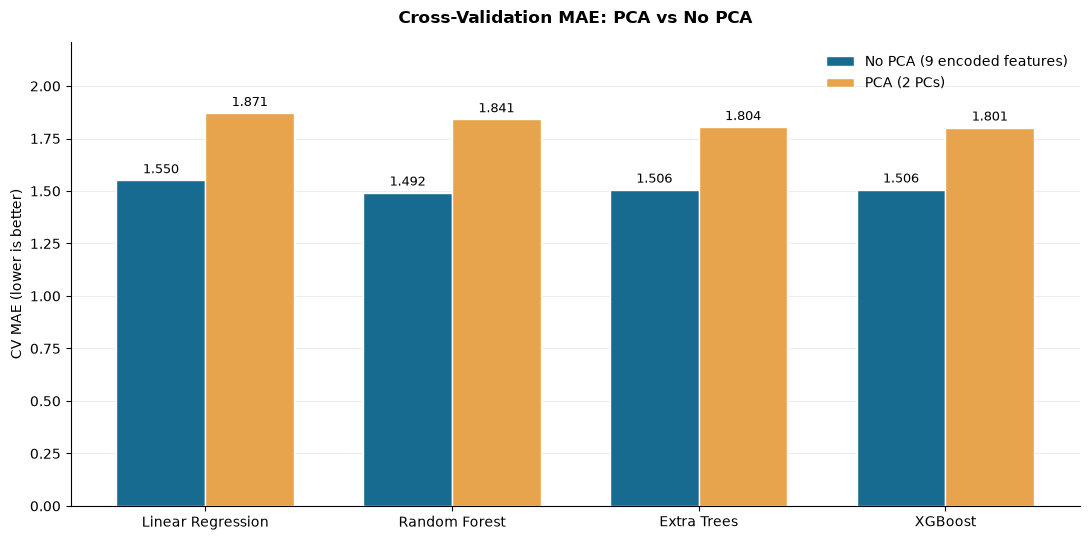

Better feature setting by model:


,Better setting
Model,
Linear Regression,No PCA (9 encoded features)
Random Forest,No PCA (9 encoded features)
Extra Trees,No PCA (9 encoded features)
XGBoost,No PCA (9 encoded features)


In [15]:
grouped_metric_plot(cv, 'CV_MAE', 'Cross-Validation MAE: PCA vs No PCA', 'CV MAE (lower is better)')

## Visualization 2 — Test MAE
Lower is better. MAE measures the average absolute difference between predicted and actual ring counts.

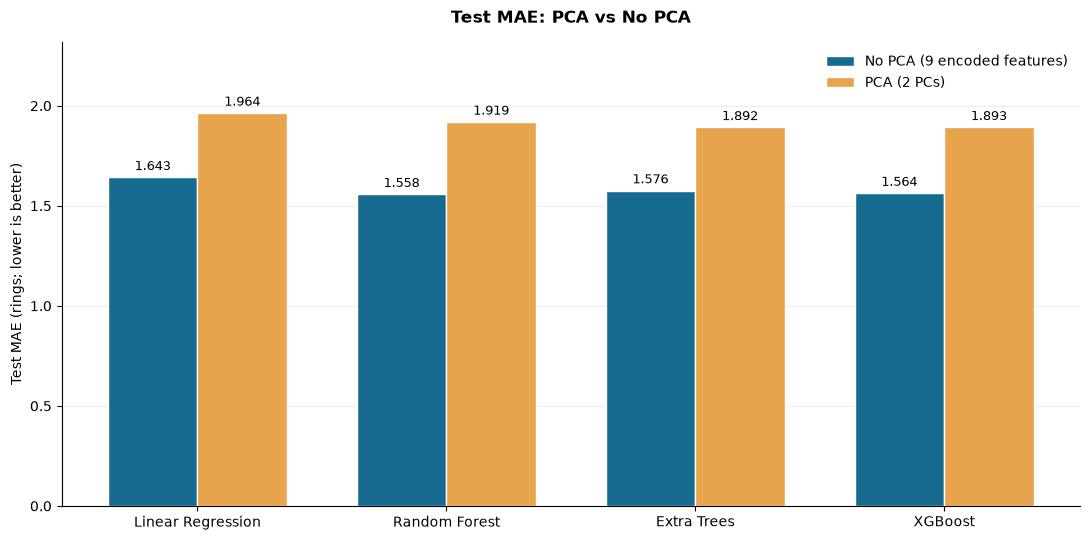

Better feature setting by model:


,Better setting
Model,
Linear Regression,No PCA (9 encoded features)
Random Forest,No PCA (9 encoded features)
Extra Trees,No PCA (9 encoded features)
XGBoost,No PCA (9 encoded features)


In [16]:
grouped_metric_plot(test, 'MAE', 'Test MAE: PCA vs No PCA', 'Test MAE (rings; lower is better)')

## Visualization 3 — Test RMSE
Lower is better. RMSE penalizes large prediction errors more strongly than MAE.

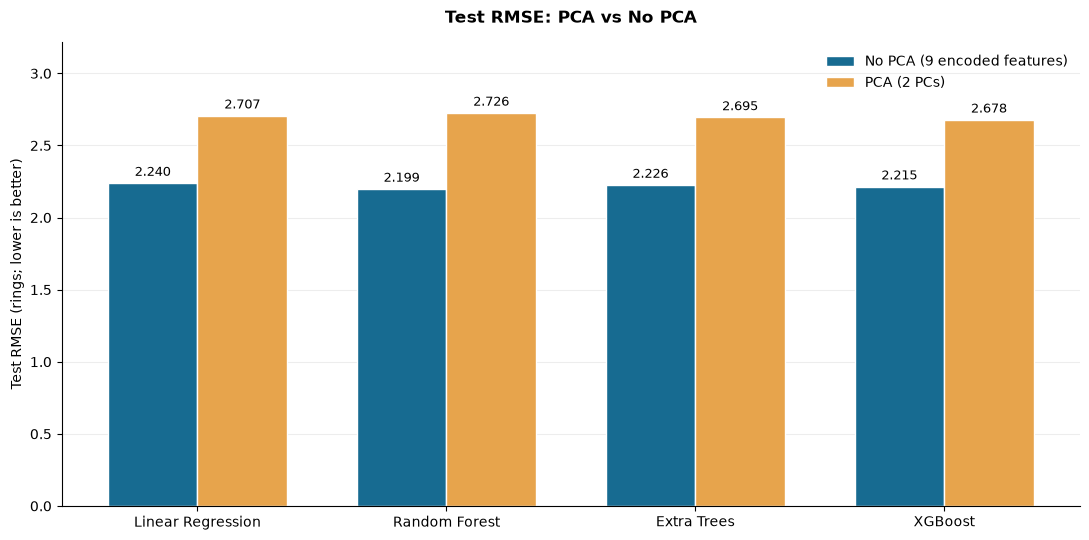

Better feature setting by model:


,Better setting
Model,
Linear Regression,No PCA (9 encoded features)
Random Forest,No PCA (9 encoded features)
Extra Trees,No PCA (9 encoded features)
XGBoost,No PCA (9 encoded features)


In [11]:
grouped_metric_plot(test, 'RMSE', 'Test RMSE: PCA vs No PCA', 'Test RMSE (rings; lower is better)')

## Visualization 4 — Test R²
Higher is better. R² measures the proportion of variation in ring counts explained by the predictions on the test set.

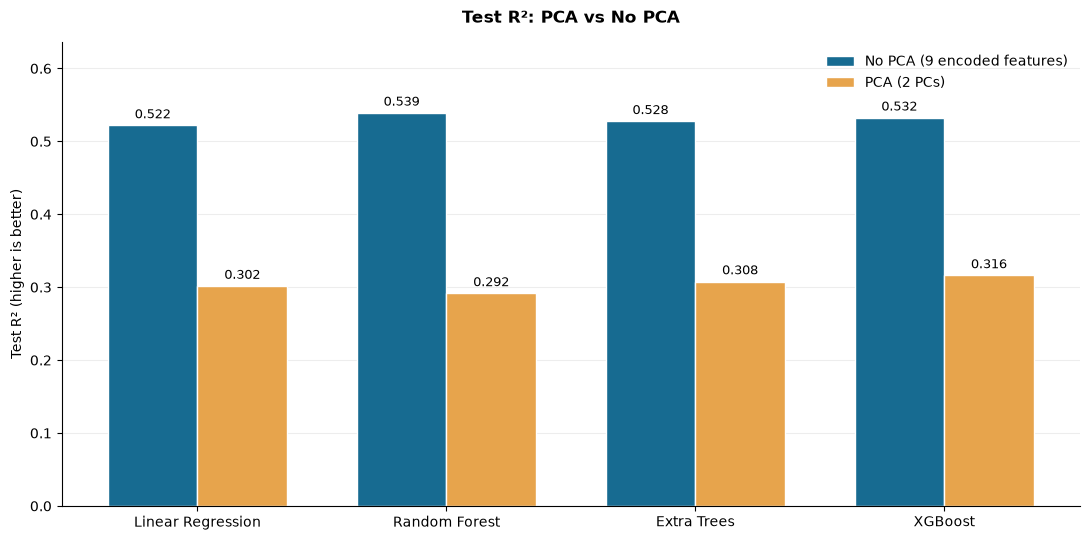

Better feature setting by model:


,Better setting
Model,
Linear Regression,No PCA (9 encoded features)
Random Forest,No PCA (9 encoded features)
Extra Trees,No PCA (9 encoded features)
XGBoost,No PCA (9 encoded features)


In [12]:
grouped_metric_plot(test, 'R2', 'Test R²: PCA vs No PCA', 'Test R² (higher is better)', higher_is_better=True)